In [229]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from math import inf
import seaborn as sns
import matplotlib.pyplot as plt

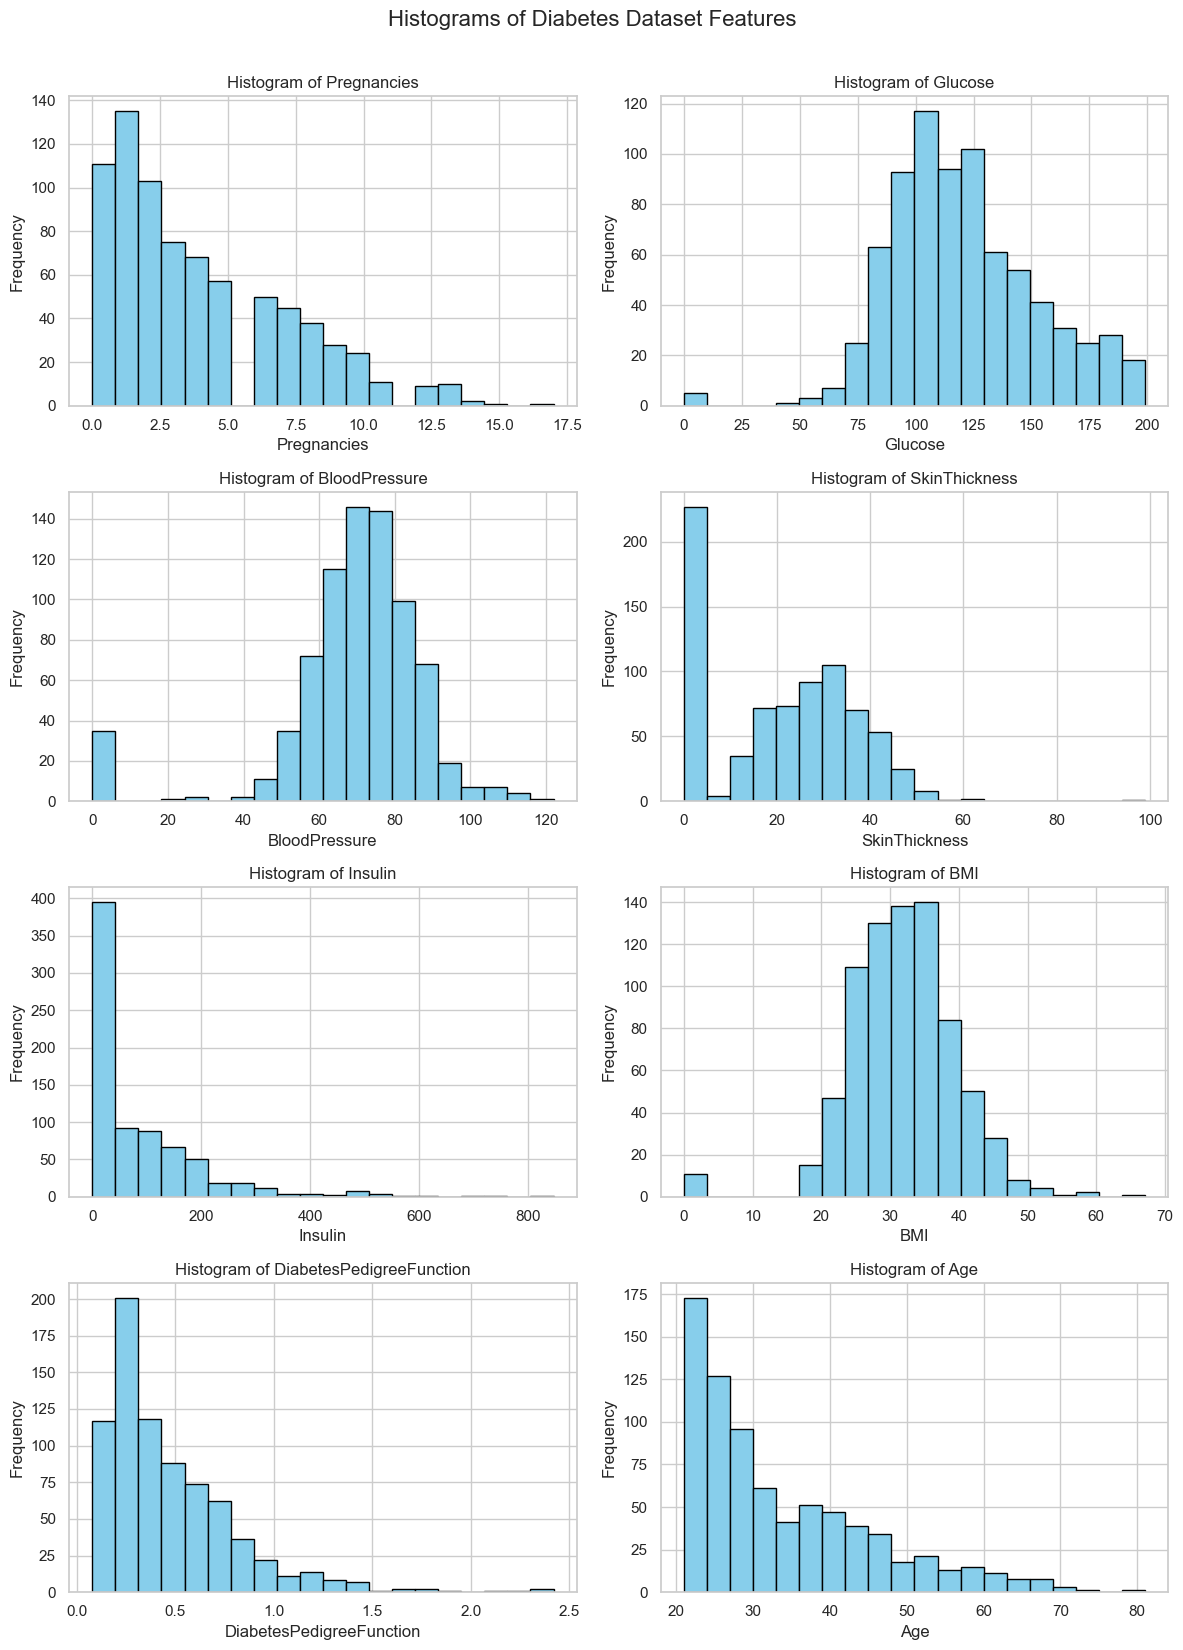

In [230]:
data = pd.read_csv('../dataset/diabetes.csv', header=None)

feature_names = data.iloc[0].values
data = data.drop(0)
data.columns = feature_names
data = data.apply(pd.to_numeric)

features = data.drop(columns=['Outcome'])
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 16))
axes = axes.flatten()

for i, column in enumerate(features.columns):
    axes[i].hist(features[column], bins=20, color='skyblue', edgecolor='black')
    axes[i].set_title(f'Histogram of {column}')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Frequency')
    axes[i].grid(True)

plt.tight_layout()
fig.suptitle('Histograms of Diabetes Dataset Features', fontsize=16, y=1.03)
plt.show()

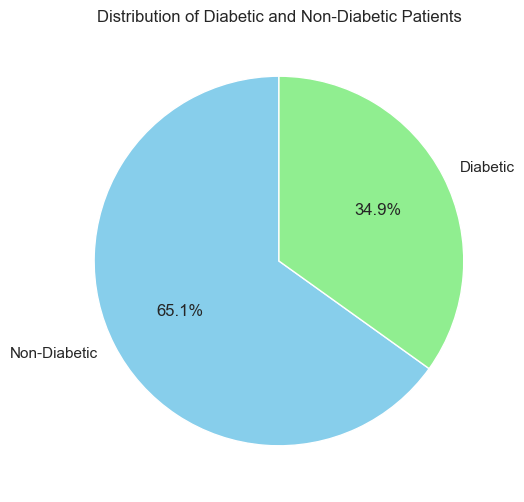

In [231]:
outcome_counts = data['Outcome'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(outcome_counts, labels=['Non-Diabetic', 'Diabetic'], autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightgreen'])
plt.title('Distribution of Diabetic and Non-Diabetic Patients')
plt.show()

In [232]:
data = pd.read_csv('../dataset/diabetes_scale.csv')
print(data.describe())

X = data.drop('label', axis=1).values
y = data['label'].values
y = np.where(y == -1, 0, 1)

scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_standardized, y, test_size=0.2, random_state=42)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

X_train = torch.tensor(X_train_smote, dtype=torch.float32)
y_train = torch.tensor(y_train_smote, dtype=torch.float32).unsqueeze(1)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

            label   feature_1   feature_2   feature_3   feature_4   feature_5  \
count  768.000000  768.000000  768.000000  768.000000  768.000000  768.000000   
mean     0.302083   -0.547641    0.215020    0.132877   -0.585122   -0.811349   
std      0.953903    0.396421    0.321333    0.317308    0.322267    0.272444   
min     -1.000000   -1.000000   -1.000000   -1.000000   -1.000000   -1.000000   
25%     -1.000000   -0.882353   -0.005025    0.016393   -1.000000   -1.000000   
50%      1.000000   -0.647059    0.175879    0.180328   -0.535354   -0.927896   
75%      1.000000   -0.294118    0.409547    0.311475   -0.353535   -0.699173   
max      1.000000    1.000000    1.000000    1.000000    1.000000    1.000000   

        feature_6   feature_7   feature_8  
count  768.000000  768.000000  768.000000  
mean    -0.046421   -0.663641   -0.591971  
std      0.234997    0.282945    0.392008  
min     -1.000000   -1.000000   -1.000000  
25%     -0.186289   -0.858455   -0.900000  
50%   

In [233]:
class Perceptron(nn.Module):
    def __init__(self, input_size):
        super(Perceptron, self).__init__()
        self.fc = nn.Linear(input_size, 1)

    def forward(self, x):
        out = torch.sigmoid(self.fc(x))
        return out

def train_and_test(X_train, y_train, X_test, y_test, criterion, optimizer_func, lr, num_epochs=100):
    input_size = X_train.shape[1]
    model = Perceptron(input_size)
    
    optimizer = optimizer_func(model.parameters(), lr=lr)
    losses = []
    accuracies = []
    
    for epoch in range(num_epochs):
        model.train()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        
        model.eval()
        with torch.no_grad():
            predictions = model(X_test).round()
            accuracy = (predictions.eq(y_test).sum().item()) / y_test.shape[0]
            accuracies.append(accuracy)

    return model, losses, accuracies

In [234]:
configurations = [
    {"criterion": nn.BCELoss(), "optimizer_func": optim.SGD, "learning_rates": [0.001, 0.01, 0.1], "label": "SGD"},
    {"criterion": nn.BCELoss(), "optimizer_func": optim.Adam, "learning_rates": [0.001, 0.01, 0.1], "label": "Adam"},
]

results = {}
for config in configurations:
    for lr in config['learning_rates']:
        print(f"Training with {config['label']} and learning rate {lr}")
        label = f"{config['label']}_LR_{lr}"
        model, losses, accuracies = train_and_test(X_train, y_train, X_test, y_test,
                                               criterion=config["criterion"],
                                               optimizer_func=config["optimizer_func"],
                                               lr=lr,
                                               num_epochs=100)
        results[label] = {"losses": losses, "accuracies": accuracies, "model": model}

Training with SGD and learning rate 0.001
Training with SGD and learning rate 0.01
Training with SGD and learning rate 0.1
Training with Adam and learning rate 0.001
Training with Adam and learning rate 0.01
Training with Adam and learning rate 0.1


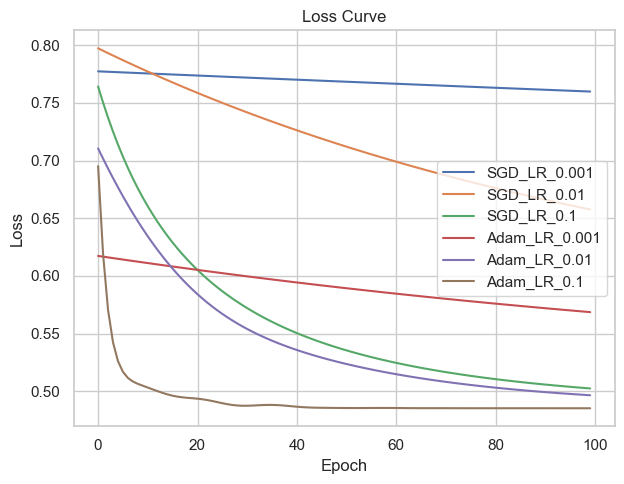

In [235]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

for label, result in results.items():
    plt.plot(result["losses"], label=label)

plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

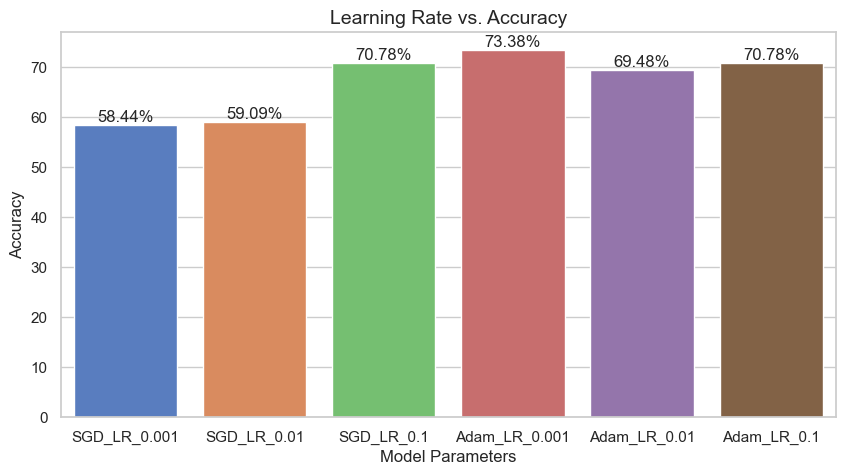

In [236]:
learning_rates = []
mean_accuracies = []

for label, result in results.items():
    final_accuracy = result["accuracies"][-1] * 100
    learning_rates.append(label)
    mean_accuracies.append(final_accuracy)

plt.figure(figsize=(10, 5))
sns.set(style="whitegrid")
ax = sns.barplot(x=learning_rates, y=mean_accuracies, palette="muted")

for i, acc in enumerate(mean_accuracies):
    ax.text(i, acc + 0.1, f"{acc:.2f}%", ha="center", va="bottom")

plt.title("Learning Rate vs. Accuracy", fontsize=14)
plt.xlabel("Model Parameters")
plt.ylabel("Accuracy")
plt.show()

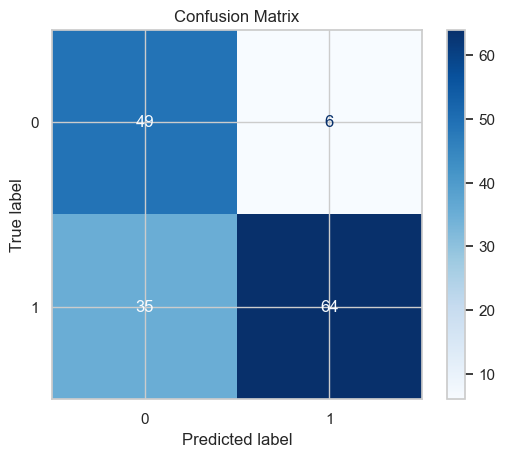

In [237]:
highest_accuracy = -inf
highest_accuracy_model = None
highest_accuracy_model_label = None
for label, result in results.items():
    if result['accuracies'][-1] > highest_accuracy:
        highest_accuracy = result['accuracies'][-1]
        highest_accuracy_model = result['model']
        highest_accuracy_model_label = label

highest_accuracy_model.eval()
with torch.no_grad():
    y_pred_prob = highest_accuracy_model(X_test)
    y_pred = (y_pred_prob >= 0.5).float()

y_pred = y_pred.numpy().flatten()
y_test = y_test.numpy().flatten()
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

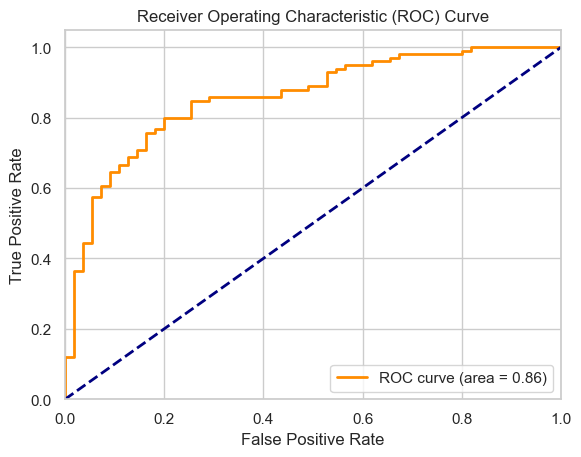

In [238]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob.numpy().flatten())
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()